# 05 — Zone Clustering

Derives 4–6 geographically contiguous zones from the gap surface using
spatial clustering on `[gap_score, centroid_x, centroid_y]`.

Tries both HDBSCAN and k-means (k=3–7), evaluates silhouette scores,
then dissolves contiguous block groups of the same cluster into zone polygons.

**Output:** `data/processed/zones.gpkg`

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import hdbscan

In [2]:
gap_gdf = gpd.read_file('../data/processed/gap_surface.gpkg')
gap_gdf = gap_gdf.to_crs('EPSG:32610')  # UTM Zone 10N for meaningful distances

# Feature matrix: gap_score + centroid coords
centroids = gap_gdf.geometry.centroid
X = pd.DataFrame({
    'gap_score': gap_gdf['gap_score'],
    'centroid_x': centroids.x,
    'centroid_y': centroids.y,
}).dropna()

gap_clean = gap_gdf.loc[X.index].copy()
X_scaled = StandardScaler().fit_transform(X)

print(f"Block groups in clustering: {len(X)}")

Block groups in clustering: 575


ERROR 1: PROJ: proj_create_from_database: Open of /home/simonhans/miniforge3/envs/snotrac-gaps/share/proj failed


  k=3: silhouette=0.3912
  k=4: silhouette=0.4038
  k=5: silhouette=0.3666
  k=6: silhouette=0.3820
  k=7: silhouette=0.3706

Best k-means k: 4


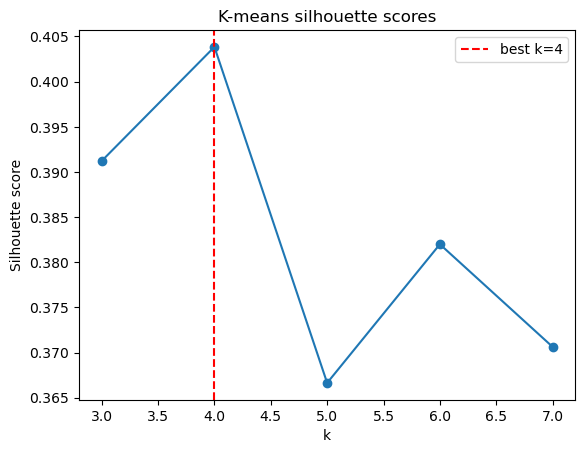

In [3]:
# --- K-Means: evaluate k=3..7 ---
sil_scores = {}
for k in range(3, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    sil_scores[k] = sil
    print(f"  k={k}: silhouette={sil:.4f}")

best_k = max(sil_scores, key=sil_scores.get)
print(f"\nBest k-means k: {best_k}")

plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o')
plt.xlabel('k')
plt.ylabel('Silhouette score')
plt.title('K-means silhouette scores')
plt.axvline(best_k, color='red', ls='--', label=f'best k={best_k}')
plt.legend()
plt.show()

In [4]:
# --- HDBSCAN ---
hdb = hdbscan.HDBSCAN(min_cluster_size=8, min_samples=3)
hdb_labels = hdb.fit_predict(X_scaled)
n_hdb_clusters = len(set(hdb_labels)) - (1 if -1 in hdb_labels else 0)
n_noise = (hdb_labels == -1).sum()
print(f"HDBSCAN clusters: {n_hdb_clusters}, noise points: {n_noise}/{len(hdb_labels)}")

# If HDBSCAN produces 4-6 clusters with low noise, prefer it
# Otherwise fall back to best k-means k

HDBSCAN clusters: 5, noise points: 167/575


In [5]:
# Choose clustering method — edit this cell as needed after reviewing results above
USE_HDBSCAN = (4 <= n_hdb_clusters <= 6) and (n_noise / len(hdb_labels) < 0.10)

if USE_HDBSCAN:
    print(f"Using HDBSCAN ({n_hdb_clusters} clusters)")
    gap_clean['zone_id'] = hdb_labels
    # Assign noise points to nearest non-noise cluster
    if n_noise > 0:
        from sklearn.neighbors import KNeighborsClassifier
        mask_labeled = hdb_labels != -1
        knn = KNeighborsClassifier(n_neighbors=1)
        knn.fit(X_scaled[mask_labeled], hdb_labels[mask_labeled])
        gap_clean.loc[~mask_labeled, 'zone_id'] = knn.predict(X_scaled[~mask_labeled])
else:
    print(f"Using k-means (k={best_k})")
    km_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    gap_clean['zone_id'] = km_final.fit_predict(X_scaled)

Using k-means (k=4)


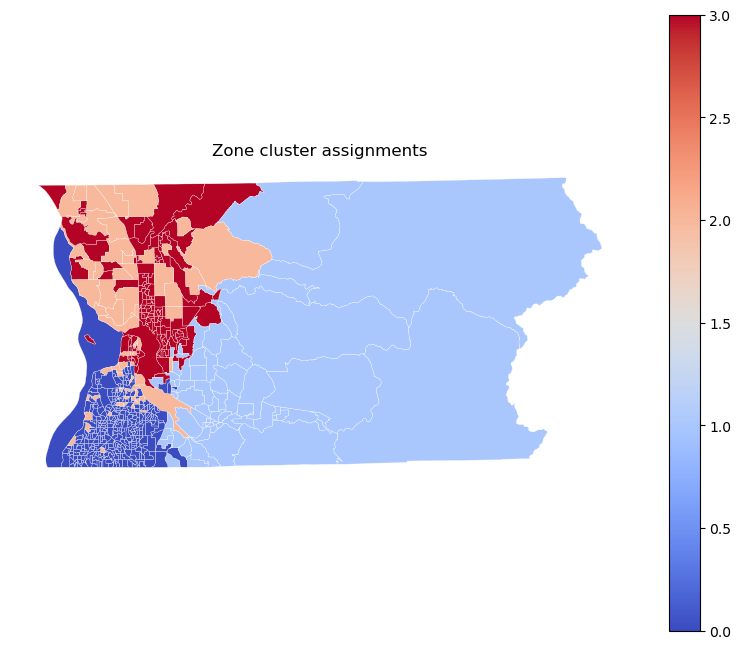

In [9]:
# QA: map cluster assignments
fig, ax = plt.subplots(figsize=(10, 8))
gap_clean.plot(column='zone_id', cmap='coolwarm', legend=True,
               linewidth=0.2, edgecolor='white', ax=ax)
ax.set_title('Zone cluster assignments')
ax.set_axis_off()
plt.savefig('../data/outputs/zone_clusters.png')

plt.show()

In [10]:
# Dissolve block groups into zone polygons
zones = gap_clean.dissolve(by='zone_id', aggfunc={
    'gap_score': 'mean',
    'vulnerability_index': 'mean',
    'norm_accessibility': 'mean',
}).reset_index()

zones = zones.rename(columns={
    'gap_score': 'mean_gap_score',
    'vulnerability_index': 'mean_vulnerability',
    'norm_accessibility': 'mean_accessibility',
})

# Rank-based labeling — assigns one distinct label per zone regardless of
# absolute scale. Works for any number of zones without threshold recalibration.
remaining = set(zones.index)
labels = {}

# 1. Highest gap → top priority intervention target
idx = zones.loc[list(remaining), 'mean_gap_score'].idxmax()
labels[idx] = 'High Gap - Underserved'
remaining.remove(idx)

# 2. Highest accessibility → well-served urban core
idx = zones.loc[list(remaining), 'mean_accessibility'].idxmax()
labels[idx] = 'Well Served - Urban Core'
remaining.remove(idx)

# 3. Highest vulnerability among remainder → vulnerable but isolated
idx = zones.loc[list(remaining), 'mean_vulnerability'].idxmax()
labels[idx] = 'Vulnerable - Limited Access'
remaining.remove(idx)

# 4. Remaining → lowest gap + vulnerability (rural low-need)
for idx in remaining:
    labels[idx] = 'Low Need - Rural'

zones['zone_label'] = zones.index.map(labels)

print(zones[['zone_id', 'zone_label', 'mean_gap_score', 'mean_vulnerability', 'mean_accessibility']].to_string())

   zone_id                   zone_label  mean_gap_score  mean_vulnerability  mean_accessibility
0        0     Well Served - Urban Core        0.064705            0.138926            0.071005
1        1  Vulnerable - Limited Access        0.123212            0.143956            0.008317
2        2       High Gap - Underserved        0.197860            0.255944            0.010512
3        3             Low Need - Rural        0.073953            0.131089            0.040579


In [11]:
# Save zones + re-join zone_id back to block groups for 06_maps
zones.to_file('../data/processed/zones.gpkg', driver='GPKG')
print(f"Zones saved → data/processed/zones.gpkg")

# Save block group gap surface with zone_id attached
gap_clean.to_file('../data/processed/gap_surface.gpkg', driver='GPKG')
print(f"Gap surface (with zone_id) → data/processed/gap_surface.gpkg")

Zones saved → data/processed/zones.gpkg
Gap surface (with zone_id) → data/processed/gap_surface.gpkg
